# Default rates by origination vintage

One row per loan from `data/processed/loans.parquet`: a 10% loan sample of Fannie Mae's 2015Q1–2017Q4 originations. `default_24m` is 1 if the loan went 180+ days delinquent or ended with a loss-type exit within 24 months of its first payment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from fannie_default.evaluate import STORM_STATES
from fannie_default.vintage import add_bands, default_rate_by

REPORTS = Path("../reports")
loans = add_bands(pd.read_parquet("../data/processed/loans.parquet"))
loans["region"] = loans["STATE"].where(loans["STATE"].isin(STORM_STATES), "rest of US")
print(f"{len(loans):,} loans, {loans['default_24m'].sum():,} defaults ({loans['default_24m'].mean():.3%})")

602,838 loans, 1,448 defaults (0.240%)


## By vintage

In [2]:
by_vintage = default_rate_by(loans, "vintage")
by_vintage.style.format({"default_rate": "{:.3%}", "loans": "{:,}"})

,loans,defaults,default_rate
vintage,,,
2015Q1,"45,336",69,0.152%
2015Q2,"52,462",89,0.170%
2015Q3,"47,706",91,0.191%
2015Q4,"41,545",67,0.161%
2016Q1,"41,931",100,0.238%
2016Q2,"56,960",147,0.258%
2016Q3,"71,748",184,0.256%
2016Q4,"63,945",151,0.236%
2017Q1,"42,510",163,0.383%


## The 2017 hurricanes

Harvey (Texas, August 2017) and Irma (Florida, September 2017) put many borrowers into forbearance, and missed payments kept counting while they were in it. A loan's 24-month window has to run at least six months past September 2017 for a storm delinquency to reach 180 days, which is why the spike starts with the 2016Q1 vintage rather than 2015Q4, and fades for 2017Q4 loans whose windows start after the storms.

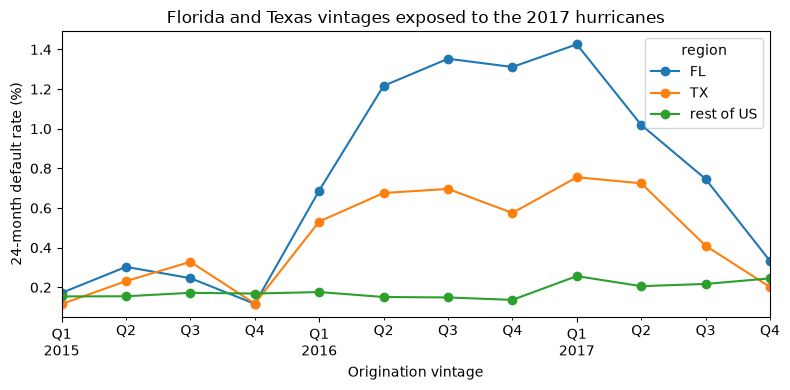

In [3]:
by_region = default_rate_by(loans, ["vintage", "region"])["default_rate"].unstack()
ax = by_region.mul(100).plot(marker="o", figsize=(8, 4))
ax.set_xlabel("Origination vintage")
ax.set_ylabel("24-month default rate (%)")
ax.set_title("Florida and Texas vintages exposed to the 2017 hurricanes")
plt.tight_layout()
plt.savefig(REPORTS / "default_rate_by_vintage_region.png", dpi=150)

## Credit score bands

fico_band,620-679,680-739,740+
vintage,,,
2015Q1,0.76%,0.32%,0.03%
2015Q2,0.64%,0.31%,0.06%
2015Q3,0.95%,0.25%,0.06%
2015Q4,0.85%,0.24%,0.03%
2016Q1,1.00%,0.37%,0.08%
2016Q2,1.12%,0.41%,0.10%
2016Q3,1.51%,0.45%,0.08%
2016Q4,1.14%,0.39%,0.08%
2017Q1,1.51%,0.49%,0.15%


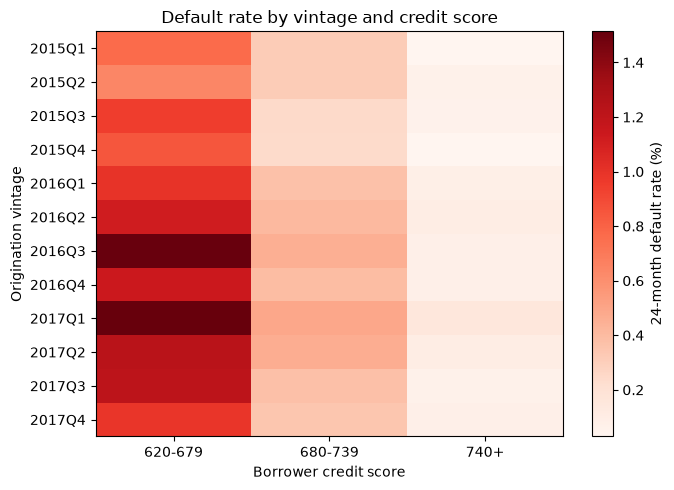

In [4]:
# Fannie Mae's minimum credit score is 620, so "<620" and "missing" hold a few hundred loans; leave them off the map.
main_bands = loans[loans["fico_band"].isin(["620-679", "680-739", "740+"])]
fico = main_bands.pivot_table(index="vintage", columns="fico_band", values="default_24m", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(fico.mul(100).to_numpy(), aspect="auto", cmap="Reds")
ax.set_xticks(range(len(fico.columns)), fico.columns)
ax.set_yticks(range(len(fico.index)), fico.index.astype(str))
ax.set_xlabel("Borrower credit score")
ax.set_ylabel("Origination vintage")
fig.colorbar(im, label="24-month default rate (%)")
ax.set_title("Default rate by vintage and credit score")
plt.tight_layout()
plt.savefig(REPORTS / "default_rate_fico_heatmap.png", dpi=150)
fico.style.format("{:.2%}")

In [5]:
default_rate_by(loans, "fico_band").style.format({"default_rate": "{:.3%}", "loans": "{:,}"})

,loans,defaults,default_rate
fico_band,,,
<620,13,0,0.000%
620-679,"51,190",561,1.096%
680-739,"155,752",583,0.374%
740+,"395,594",304,0.077%
missing,289,0,0.000%


In [6]:
default_rate_by(loans, "ltv_band").style.format({"default_rate": "{:.3%}", "loans": "{:,}"})

,loans,defaults,default_rate
ltv_band,,,
<=80,"432,365",782,0.181%
80-90,"68,304",199,0.291%
90-95,"81,067",344,0.424%
>95,"21,102",123,0.583%


## Takeaways

- **Credit score dominates.** Borrowers at 620–679 default at 1.10%, about 14 times the 0.077% of borrowers at 740+; 680–739 sits between at 0.37%. Every vintage keeps that ordering.
- **Loan-to-value adds a smaller, steady gradient:** 0.18% at 80% LTV or less, rising to 0.58% above 95%.
- **Outside Florida and Texas, vintages barely differ** (0.14–0.26%). The jump in 2016–2017 vintages is mostly the 2017 hurricanes, which origination data cannot predict, so every model is also scored with Florida and Texas excluded.
- **The 2017 test vintages run hotter than training** (0.30% vs 0.21%), partly from the storms and partly from a slight rise elsewhere in 2017. An out-of-time test is meant to expose exactly this kind of drift.